# Phase 4 — Baseline Recommendation Models on MovieLens 1M (Per-User Temporal)

**Objective:** Compare Popularity, MF-BPR and LightGCN using the **MovieLens 1M** Per-User Temporal Split. Full-ranking evaluation at K=10, without official Test evaluation.

**Safety:** Rebuild MovieLens 1M preprocessing and graph artifacts before training. Existing checkpoints/results will be overwritten by the training script.


## 1. Environment

In [40]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

def find_project_root():
    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (
            (candidate / "configs" / "baselines.yaml").exists()
            and (candidate / "src" / "models").is_dir()
        ):
            return candidate

    raise FileNotFoundError("Project root not found")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULT_DIR = PROJECT_ROOT / "experiments" / "phase4"

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Project:", PROJECT_ROOT)
print("CUDA:", torch.cuda.is_available())

Python: e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
Project: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender
CUDA: False


## 2. Verify Phase 2 and Phase 3 artifacts

In [41]:
import yaml
from src.data.preprocessing import run_pipeline
from src.data.graph_builder import run_graph_pipeline

DATA_ROOT = PROJECT_ROOT / "data"
RAW_DIR = DATA_ROOT / "raw" / "ml-1m"
assert (RAW_DIR / "movies.csv").exists(), "Missing data/raw/ml-1m/movies.csv"
assert (RAW_DIR / "ratings.csv").exists(), "Missing data/raw/ml-1m/ratings.csv"

preprocess_metadata = run_pipeline(
    raw_dir=RAW_DIR,
    output_root=DATA_ROOT,
    split_method="per_user_temporal",
)
graph_metadata = run_graph_pipeline(DATA_ROOT)

with open(DATA_ROOT / "splits" / "split_metadata.json", encoding="utf-8") as f:
    split_metadata = json.load(f)
with open(DATA_ROOT / "graphs" / "graph_metadata.json", encoding="utf-8") as f:
    graph_metadata = json.load(f)
with open(PROJECT_ROOT / "configs" / "baselines.yaml", encoding="utf-8") as f:
    baseline_config = yaml.safe_load(f)

assert split_metadata["split_method"] == "per_user_temporal"
assert graph_metadata["split_method"] == "per_user_temporal"
assert int(split_metadata["num_users"]) == 6040, "Artifacts are not from MovieLens 1M"
assert baseline_config["project"]["top_k"] == 10, "Current metric labels assume K=10"

train = pd.read_csv(DATA_ROOT / "splits" / "train.csv")
val = pd.read_csv(DATA_ROOT / "splits" / "val.csv")
test = pd.read_csv(DATA_ROOT / "splits" / "test.csv")
evaluation_users = pd.read_csv(DATA_ROOT / "splits" / "evaluation_users.csv")

assert len(train) == split_metadata["train_count"]
assert len(val) == split_metadata["val_count"]
assert len(test) == split_metadata["test_count"]
assert int(train["is_positive"].sum()) == graph_metadata["train_positive_edges"]

graph_path = DATA_ROOT / "graphs" / "train_graph.pt"
train_graph = torch.load(graph_path, map_location="cpu", weights_only=False)
actual_edges = set(map(tuple, train_graph[("user", "rates", "movie")].edge_index.T.tolist()))
expected_edges = set(map(tuple, train.loc[train["is_positive"] == 1, ["user_idx", "movie_idx"]].to_numpy().tolist()))
assert actual_edges == expected_edges, "Train graph does not match Train split"

eligible_val_users = set(evaluation_users.loc[evaluation_users["eligible_val"] == True, "user_idx"].astype(int))
assert len(eligible_val_users) == split_metadata["num_eligible_val_users"]

print("MovieLens 1M artifacts rebuilt and verified: PASSED")
print("Users / Movies / Ratings:", preprocess_metadata["num_users"], preprocess_metadata["num_movies"], preprocess_metadata["num_interactions"])
print("Train / Validation / Test:", len(train), len(val), len(test))
print("Eligible Validation users:", len(eligible_val_users))


MovieLens 1M artifacts rebuilt and verified: PASSED
Users / Movies / Ratings: 6040 3883 1000209
Train / Validation / Test: 799086 100613 100510
Eligible Validation users: 5776


## 3. Unit tests — before training

In [42]:
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-p", "test_*.py", "-v"],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
print(result.stdout)
print(result.stderr)
assert result.returncode == 0, "Unit tests failed; do not start training"
print("All project unit tests: PASSED")



e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
test_bpr_loss (test_baselines.TestBaselines.test_bpr_loss) ... ok
test_full_ranking_filters_history (test_baselines.TestBaselines.test_full_ranking_filters_history) ... ok
test_lightgcn_output_shape (test_baselines.TestBaselines.test_lightgcn_output_shape) ... ok
test_mf_output_shape (test_baselines.TestBaselines.test_mf_output_shape) ... ok
test_multiple_negative_sampling_shape_and_history (test_baselines.TestBaselines.test_multiple_negative_sampling_shape_and_history) ... ok
test_negative_sampling (test_baselines.TestBaselines.test_negative_sampling) ... ok
test_negative_sampling_never_uses_observed_low_ratings (test_baselines.TestBaselines.test_negative_sampling_never_uses_observed_low_ratings) ... ok
test_popularity (test_baselines.TestBaselines.test_popularity) ... 

## 4. Train three baselines

**Warning:** This executes `scripts/train_baselines.py`, overwriting working checkpoints and Phase 4 outputs. Confirm that your Global Temporal results are backed up. The current script uses CPU even when CUDA is available.

In [43]:
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "scripts/train_baselines.py"
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0, (
    "Baseline training failed"
)

print("Baseline training: PASSED")

Epoch 001 | Loss: 0.56829 | NDCG@10: 0.05685
Epoch 002 | Loss: 0.43078 | NDCG@10: 0.06012
Epoch 003 | Loss: 0.42570 | NDCG@10: 0.05739
Epoch 004 | Loss: 0.42592 | NDCG@10: 0.05728
Epoch 005 | Loss: 0.42551 | NDCG@10: 0.05792
Epoch 006 | Loss: 0.42480 | NDCG@10: 0.05744
Epoch 007 | Loss: 0.42455 | NDCG@10: 0.05755
Epoch 008 | Loss: 0.42491 | NDCG@10: 0.05707
Epoch 009 | Loss: 0.42523 | NDCG@10: 0.05896
Early stopping triggered
Epoch 001 | Loss: 0.69314 | NDCG@10: 0.00312
Epoch 002 | Loss: 0.69314 | NDCG@10: 0.00315
Epoch 003 | Loss: 0.69314 | NDCG@10: 0.00327
Epoch 004 | Loss: 0.69314 | NDCG@10: 0.00355
Epoch 005 | Loss: 0.69314 | NDCG@10: 0.00374
Epoch 006 | Loss: 0.69314 | NDCG@10: 0.00422
Epoch 007 | Loss: 0.69314 | NDCG@10: 0.00509
Epoch 008 | Loss: 0.69314 | NDCG@10: 0.00624
Epoch 009 | Loss: 0.69314 | NDCG@10: 0.00843
Epoch 010 | Loss: 0.69314 | NDCG@10: 0.01251
Epoch 011 | Loss: 0.69314 | NDCG@10: 0.02025
Epoch 012 | Loss: 0.69314 | NDCG@10: 0.02958
Epoch 013 | Loss: 0.69314 | ND

## 5. Validation results

In [44]:
results = pd.read_csv(
    RESULT_DIR / "validation_results.csv"
)

display(results)

,model,users_evaluated,Precision@10,Recall@10,NDCG@10
0,Popularity,5776,0.045274,0.048219,0.057826
1,MF-BPR,5776,0.046970,0.053420,0.060125
2,LightGCN,5776,0.045014,0.047366,0.057338


In [45]:
assert set(results["model"]) == {"Popularity", "MF-BPR", "LightGCN"}
assert results["users_evaluated"].nunique() == 1, "Models evaluated on different numbers of users"
assert int(results["users_evaluated"].iloc[0]) == len(eligible_val_users), "Some eligible users were not evaluated"
print("All models evaluated on", int(results["users_evaluated"].iloc[0]), "users")


All models evaluated on 5776 users


## 6. Compare metrics

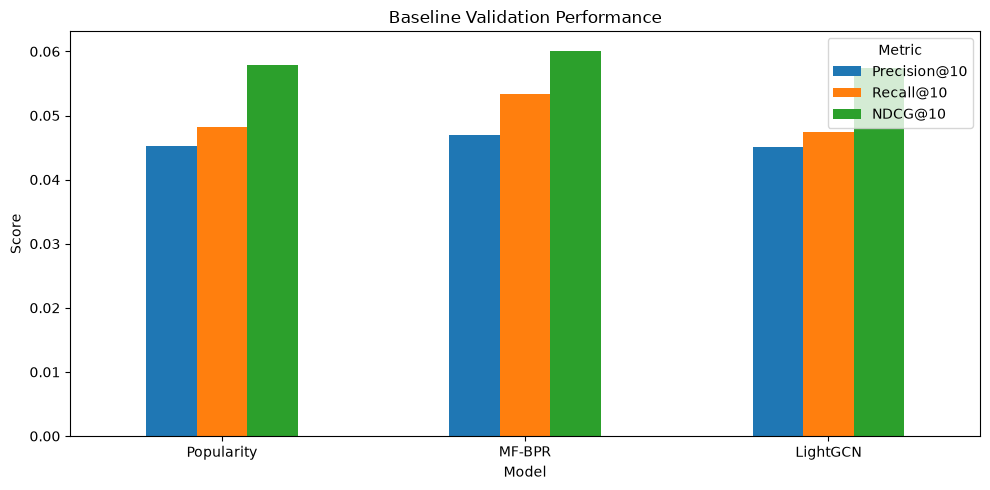

In [46]:
metrics = [
    "Precision@10",
    "Recall@10",
    "NDCG@10"
]

ax = results.set_index("model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Baseline Validation Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(title="Metric")

plt.tight_layout()
plt.show()

## 7. Training histories

In [47]:
with open(
    RESULT_DIR / "training_history.json",
    encoding="utf-8"
) as f:
    training_history = json.load(f)

for model_name, history in training_history.items():
    print(model_name)
    display(pd.DataFrame(history).tail())

MF-BPR


,epoch,loss,val_precision,val_recall,val_ndcg
4,5,0.425508,0.045395,0.048378,0.057921
5,6,0.424800,0.045222,0.048021,0.057445
6,7,0.424548,0.045083,0.047934,0.057546
7,8,0.424913,0.045014,0.046924,0.057065
8,9,0.425229,0.046434,0.050335,0.058956


LightGCN


,epoch,loss,val_precision,val_recall,val_ndcg
26,27,0.692748,0.044806,0.046750,0.056951
27,28,0.692644,0.044893,0.047088,0.057103
28,29,0.692518,0.044910,0.046867,0.057134
29,30,0.692365,0.045014,0.047040,0.057281
30,31,0.692182,0.045014,0.046904,0.057210


## 8. Training loss

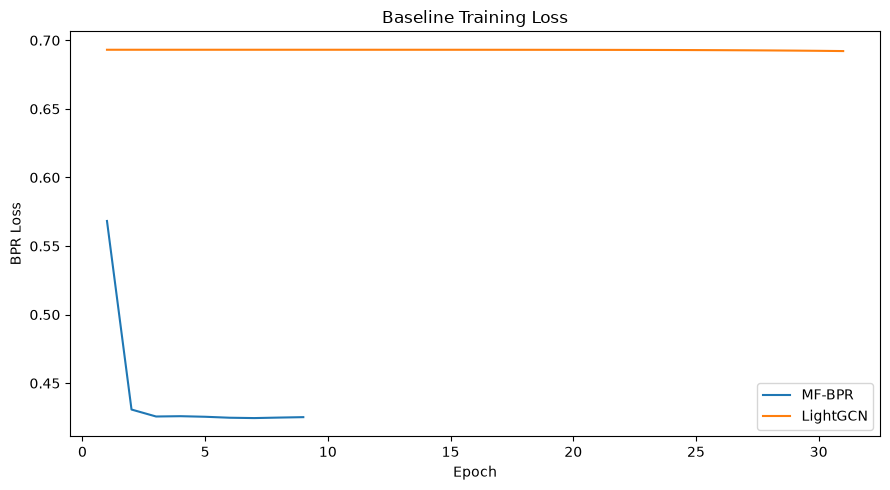

In [48]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, history in training_history.items():
    df = pd.DataFrame(history)

    ax.plot(
        df["epoch"],
        df["loss"],
        label=model_name
    )

ax.set_title("Baseline Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("BPR Loss")
ax.legend()

plt.tight_layout()
plt.show()

## 9. Validation NDCG@10

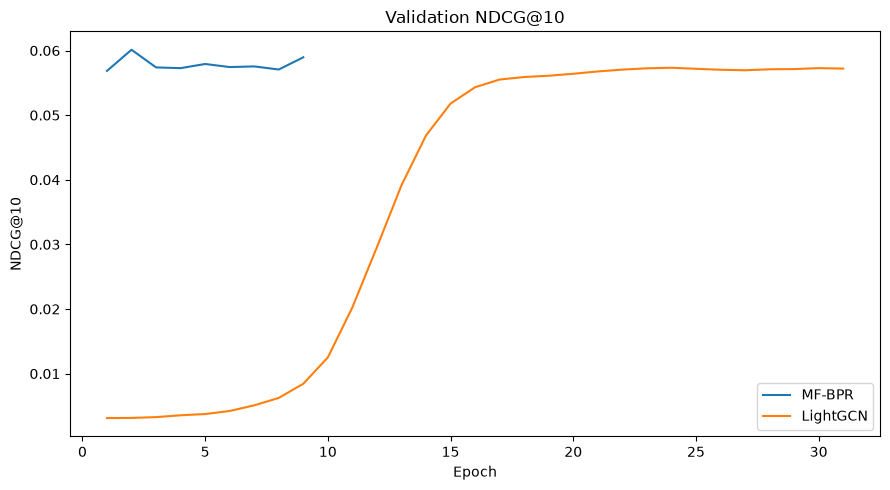

In [49]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, history in training_history.items():
    df = pd.DataFrame(history)

    ax.plot(
        df["epoch"],
        df["val_ndcg"],
        label=model_name
    )

ax.set_title("Validation NDCG@10")
ax.set_xlabel("Epoch")
ax.set_ylabel("NDCG@10")
ax.legend()

plt.tight_layout()
plt.show()

## 10. Best baseline by Validation NDCG@10

In [50]:
best_model = results.sort_values(
    "NDCG@10",
    ascending=False
).iloc[0]

print("Best baseline:", best_model["model"])
print("NDCG@10:", best_model["NDCG@10"])
print("Recall@10:", best_model["Recall@10"])
print("Precision@10:", best_model["Precision@10"])

Best baseline: MF-BPR
NDCG@10: 0.0601248229990343
Recall@10: 0.0534199052661622
Precision@10: 0.0469702216066482


## 11. User coverage statistics

In [51]:
import pandas as pd

train = pd.read_csv(PROJECT_ROOT / "data/splits/train.csv")
val = pd.read_csv(PROJECT_ROOT / "data/splits/val.csv")
test = pd.read_csv(PROJECT_ROOT / "data/splits/test.csv")

evaluation_users = pd.read_csv(
    PROJECT_ROOT / "data/splits/evaluation_users.csv"
)

train_users = set(train["user_idx"])
val_users = set(val["user_idx"])
test_users = set(test["user_idx"])

train_positive = set(
    train.loc[train["is_positive"] == 1, "user_idx"]
)

val_positive = set(
    val.loc[val["is_positive"] == 1, "user_idx"]
)

eligible = set(
    evaluation_users.loc[
        evaluation_users["eligible_val"] == True,
        "user_idx"
    ]
)

summary = pd.DataFrame({
    "Metric": [
        "Total users in dataset",
        "Users in Train",
        "Users in Validation",
        "Users in Test",
        "Users in both Train and Validation",
        "Users with positive Train interactions",
        "Users with positive Validation interactions",
        "Users with positives in both Train and Validation",
        "Eligible Validation users",
    ],
    "Count": [
        len(train_users | val_users | test_users),
        len(train_users),
        len(val_users),
        len(test_users),
        len(train_users & val_users),
        len(train_positive),
        len(val_positive),
        len(train_positive & val_positive),
        len(eligible),
    ]
})

display(summary)

,Metric,Count
0,Total users in dataset,6040
1,Users in Train,6040
2,Users in Validation,6039
3,Users in Test,6039
4,Users in both Train and Validation,6039
5,Users with positive Train interactions,6038
6,Users with positive Validation interactions,5776
7,Users with positives in both Train and Validation,5776
8,Eligible Validation users,5776


## 12. Export Phase 4 report

In [52]:
report = {
    "phase": 4,
    "dataset": "MovieLens 1M",
    "split_method": split_metadata["split_method"],
    "split_seed": split_metadata["seed"],
    "positive_threshold": split_metadata["positive_threshold"],
    "eligible_validation_users": len(eligible_val_users),
    "users_evaluated": int(results["users_evaluated"].iloc[0]),
    "environment": "colab" if "google.colab" in sys.modules else "local_or_other",
    "torch_version": torch.__version__,
    "cuda_available": bool(torch.cuda.is_available()),
    "training_device": "cpu",  # current train_baselines.py does not forward device
    "models": results.to_dict(orient="records"),
    "best_validation_model": str(best_model["model"]),
    "selection_metric": "NDCG@10",
    "evaluation": "full-ranking",
    "negative_sampling": "uniform_unobserved_train_items",
    "test_evaluated": False,
    "unit_tests": "passed",
}
RESULT_DIR.mkdir(parents=True, exist_ok=True)
report_path = RESULT_DIR / "phase4_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print("Saved:", report_path)


Saved: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\phase4\phase4_report.json
